# 03 - Cross-lingual experiment (thesis core)
**Question:** how well does a model trained on English / Italian reviews work on Roman Urdu, and how much Roman Urdu data does it need?

This notebook uses the same CPU-friendly model as Week 2 (char TF-IDF + Linear SVM) and the **same Roman Urdu test set**, so all numbers can be compared with `02_baseline`.

**Run cells top to bottom (Shift + Enter).**

In [1]:
import sys; sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

RAW = Path('../data/raw')
DOCS = Path('../docs')
LABELS = {0: 'positive', 1: 'neutral', 2: 'negative'}

## 1. Load data (same cleaning and same split as Week 2)

In [2]:
def load_multilingual(lang):
    df = pd.read_csv(RAW / f'{lang}_train.csv')
    if pd.api.types.is_numeric_dtype(df['label']):
        df['label'] = df['label'].map(LABELS)
    df['text'] = df['text'].astype(str)
    return df[['text', 'label']].dropna().drop_duplicates(subset='text')

en = load_multilingual('english')
it = load_multilingual('italian')

ru = pd.read_csv(RAW / 'roman_urdu.csv', header=None, usecols=[0, 1],
                 names=['text', 'label'], on_bad_lines='skip').dropna(subset=['text'])
ru['label'] = ru['label'].str.strip().str.lower().replace({'neative': 'negative'})
ru['text'] = ru['text'].astype(str)
ru = ru[ru['text'].str.strip() != ''].drop_duplicates(subset='text')

ru_train, ru_test = train_test_split(ru, test_size=0.2, stratify=ru['label'], random_state=42)
print('English:', len(en), ' Italian:', len(it), ' RU train:', len(ru_train), ' RU test:', len(ru_test))

English: 1839  Italian: 1839  RU train: 15700  RU test: 3926


## 2. Sanity check the labels
Read these examples. Positive examples should sound positive, negative ones negative. If they look reversed, the 0/1/2 mapping in `LABELS` is wrong and must be fixed before trusting any result.

In [3]:
pd.set_option('display.max_colwidth', 100)
for name, df in [('English', en), ('Italian', it)]:
    print(name)
    for lab in ['positive', 'negative']:
        print(' ', lab)
        for t in df[df['label'] == lab]['text'].head(3):
            print('    -', t[:100])

English
  positive
    - "Frank Gaffrey\u002c Cliff May\u002c Steve Emerson: Brilliant. \""""Looming Threats: Iran\u002c Hezb
    - "People always forget the fact that Shawn achieved so much in the age of 16 like his 1st single, EP 
    - "Winnipeg Sun: ""But make no mistake: Janet Jackson played to win. And did."" #UnbreakableWinnipeg #
  negative
    - okay i\u2019m sorry but TAYLOR SWIFT LOOKS NOTHING LIKE JACKIE O SO STOP COMPARING THE TWO. c\u2019m
    - The tragedy of only thinking up hilarious tweets for the Summer Olympics now is that in four years t
    - it looks like a beautiful night to throw myself off the Brooklyn Bridge ---@Tim_Hecht 
Italian
  positive
    - Rutelli: appoggio al governo #monti, sta lavorando bene #ballarò #osservatoriotivvù
    - @user lo so amore grazie..
    - RT @user: ditemi se non è una delle cose più belle del mondo http
  negative
    - @user mi fa sbagliare tutte le paroleeeee.
    - RT @user: Non legalizzano la #cannabis Ma iper tassano le cart

## 3. Helper: train on some data, test on Roman Urdu test set

In [4]:
def train_and_test(train_df):
    model = make_pipeline(
        TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True),
        LinearSVC(C=1.0, class_weight='balanced'),
    )
    model.fit(train_df['text'], train_df['label'])
    pred = model.predict(ru_test['text'])
    return round(accuracy_score(ru_test['label'], pred), 3), round(f1_score(ru_test['label'], pred, average='macro'), 3)

## 4. Zero-shot transfer: no Roman Urdu in training

In [5]:
rows = []
for name, df in [('English only', en), ('Italian only', it), ('English + Italian', pd.concat([en, it]))]:
    acc, f1 = train_and_test(df)
    rows.append({'trained on': name, 'train rows': len(df), 'accuracy': acc, 'macro_f1': f1})

acc, f1 = train_and_test(ru_train)
rows.append({'trained on': 'Roman Urdu (upper bound)', 'train rows': len(ru_train), 'accuracy': acc, 'macro_f1': f1})

zero_shot = pd.DataFrame(rows)
zero_shot.to_csv(DOCS / 'cross_lingual_zero_shot.csv', index=False)
zero_shot

,trained on,train rows,accuracy,macro_f1
0,English only,1839,0.407,0.362
1,Italian only,1839,0.393,0.307
2,English + Italian,3678,0.375,0.345
3,Roman Urdu (upper bound),15700,0.660,0.653


Random guessing among 3 labels gives about 0.33 macro-F1. A model trained only on English or Italian with character n-grams is expected to be close to this, because the words are different. This is the **motivation for multilingual transformers** in Week 4.

## 5. Few-shot curve: how much Roman Urdu data is needed?
Train on English + Italian plus N Roman Urdu examples, and compare with Roman Urdu alone.

In [6]:
sizes = [50, 100, 250, 500, 1000, 2500, 5000, len(ru_train)]
foreign = pd.concat([en, it])
rows = []
for n in sizes:
    sample = ru_train.sample(n=n, random_state=42) if n < len(ru_train) else ru_train
    _, f1_ru = train_and_test(sample)
    _, f1_mix = train_and_test(pd.concat([foreign, sample]))
    rows.append({'RU examples': n, 'RU only': f1_ru, 'EN+IT+RU': f1_mix})
    print(rows[-1])

curve = pd.DataFrame(rows)
curve.to_csv(DOCS / 'cross_lingual_curve.csv', index=False)
curve

{'RU examples': 50, 'RU only': 0.385, 'EN+IT+RU': 0.387}
{'RU examples': 100, 'RU only': 0.421, 'EN+IT+RU': 0.414}
{'RU examples': 250, 'RU only': 0.481, 'EN+IT+RU': 0.444}
{'RU examples': 500, 'RU only': 0.517, 'EN+IT+RU': 0.491}
{'RU examples': 1000, 'RU only': 0.541, 'EN+IT+RU': 0.525}
{'RU examples': 2500, 'RU only': 0.584, 'EN+IT+RU': 0.575}
{'RU examples': 5000, 'RU only': 0.609, 'EN+IT+RU': 0.605}
{'RU examples': 15700, 'RU only': 0.653, 'EN+IT+RU': 0.655}


,RU examples,RU only,EN+IT+RU
0,50,0.385,0.387
1,100,0.421,0.414
2,250,0.481,0.444
3,500,0.517,0.491
4,1000,0.541,0.525
5,2500,0.584,0.575
6,5000,0.609,0.605
7,15700,0.653,0.655


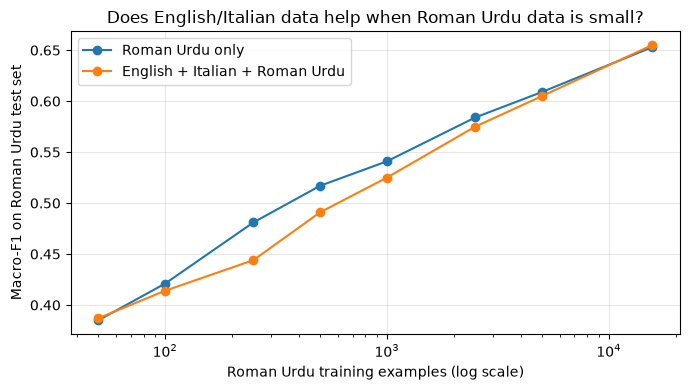

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(curve['RU examples'], curve['RU only'], marker='o', label='Roman Urdu only')
plt.plot(curve['RU examples'], curve['EN+IT+RU'], marker='o', label='English + Italian + Roman Urdu')
plt.xscale('log')
plt.xlabel('Roman Urdu training examples (log scale)')
plt.ylabel('Macro-F1 on Roman Urdu test set')
plt.title('Does English/Italian data help when Roman Urdu data is small?')
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout()
plt.savefig(DOCS / 'cross_lingual_curve.png', dpi=150)
plt.show()

## My notes (write in your own words)
1. **Zero-shot result (English / Italian only):** 
2. **Is it close to random guessing (0.33)?** 
3. **Does adding English + Italian help when Roman Urdu data is small? From how many examples does it stop helping?** 
4. **What would I expect from a multilingual transformer (Week 4)?** 

In [9]:
# ## My notes

# 1. **Zero-shot result (English / Italian only):** A model trained only on English
#    reached macro-F1 [ ] on the Roman Urdu test set, only on Italian [ ], and on
#    English + Italian [ ]. A model trained on Roman Urdu itself reaches 0.653.

# 2. **Is it close to random guessing (0.33)?** [Yes / No]. [One sentence: e.g. the
#    zero-shot scores are between 0.2x and 0.3x, so the model transfers almost
#    nothing.] Likely reason: character n-grams from English or Italian words do
#    not match Roman Urdu words, even though all three use the Latin alphabet.

# 3. **Does adding English + Italian help when Roman Urdu data is small?**
#    With 50 Roman Urdu examples: RU only [ ] vs EN+IT+RU [ ]. With 500: [ ] vs [ ].
#    With 5000: [ ] vs [ ]. Adding English and Italian [helps / does not help /
#    hurts] below about [ ] Roman Urdu examples, and the difference disappears
#    after that. For reference, Roman Urdu alone goes from 0.385 (50 examples)
#    to 0.653 (15,700 examples), so the amount of in-language data matters a lot.

# 4. **What I expect from a multilingual transformer (Week 4):** This is a
#    hypothesis, not a result yet. XLM-R was pretrained on many languages, so it
#    may transfer sentiment knowledge from English and Italian better than
#    TF-IDF, but Roman Urdu is written in Latin script with non-standard spelling,
#    which XLM-R saw little of. I expect better zero-shot results than TF-IDF, but
#    still below the Roman Urdu-trained model. I will test this in Week 4.